# Największy spadek i dobór kroku

## Funkcje z zajęć

Metoda największego spadku, złoty podział z poprawką, backtracking i funkcja Rosenbrocka - skopiowane.

In [16]:
import numpy as np
import matplotlib.pyplot as plt

In [17]:
def gd(f, grad_f, x0, step, eps=1e-5, max_iter=20_000):
    x_k = np.array(x0, dtype=float)
    g = grad_f(x_k)  # gradient
    g_norm = np.linalg.norm(g)
    X = [x_k.copy()]
    G = [g_norm]
    for k in range(max_iter):
        if not np.isfinite(g_norm) or g_norm <= eps:  # warunek stopu
            break
        p = -g  # kierunek

        def phi(alpha):
            return f(x_k + alpha * p)

        alpha_star = step(phi, -np.dot(g, g))
        x_k = x_k + alpha_star * p  # nowy punkt
        X.append(x_k.copy())
        g = grad_f(x_k)  # gradient
        g_norm = np.linalg.norm(g)
        G.append(g_norm)
    if not np.isfinite(g_norm):
        status = "brak skończonej normy"
    elif g_norm <= eps:  # warunek stopu
        status = "OK"
    else:
        status = "limit iteracji"
    return np.array(X), np.array(G), status

In [18]:
def golden(phi, a, b, tol=1e-6):
    r = (np.sqrt(5) - 1) / 2
    width_start = b - a
    width = width_start
    c = a + (1 - r) * (b - a)
    d = a + r * (b - a)
    fc = phi(c)
    fd = phi(d)
    for _ in range(100):
        if b - a <= tol * width_start:
            break
        if fc <= fd:
            b = d
            d = c
            fd = fc
            width = b - a
            c = a + (1-r) * width
            fc = phi(c)
        else:
            a = c
            c = d
            fc = fd
            width = b - a
            d = a + r * width
            fd = phi(d)
    return c if fc <= fd else d

In [19]:
def golden_fixed(phi, a=0., b=1., tol=1e-6):
    phia = phi(a)
    r = (np.sqrt(5) - 1) / 2
    for _ in range(100):
        c = a + (1 - r) * (b - a)
        if phi(c) < phia:  # znaleziono ścisły spadek
            return golden(phi, a, b, tol)
        b = c
    raise RuntimeError("Nie znaleziono kroku zmniejszającego funkcję")

In [20]:
def backtracking(phi, dphi0, alpha0=1., rho=0.5, c1=0.1):
    phi0 = phi(0.)
    alpha = alpha0
    for _ in range(100):
        if phi(alpha) <= phi0 + c1 * alpha * dphi0:  # warunek Armijo
            return alpha
        alpha = rho * alpha
    raise RuntimeError("Nie znaleziono kroku Armijo")

In [21]:
def rosen(x, a=100.):
    return (1 - x[0])**2 + a * (x[1] - x[0]**2)**2

def grad_rosen(x, a=100.):
    return np.array([2 * (x[0] - 1) - 4 * a * x[0] * (x[1] - x[0]**2),
                     2 * a * (x[1] - x[0]**2)])

In [22]:
steps = {
    "złoty podział": lambda phi, dphi0: golden_fixed(phi),
    "backtracking": backtracking,
}

## 1. Skalowanie funkcji

Dla funkcji
$$
f(x_0,x_1)=(1-x_0)^2+10(x_1-x_0^2)^2
$$
zbadaj minimalizację $F_s(x)=s f(x)$ dla $s\in\{0.01,1,100\}$, ze startu $(-1.2,1)$.

Stosuj warunek stopu $\|\nabla F_s(x)\|\leq 10^{-5}$. Prezentuj wartości oryginalnej funkcji $f$ i normy jej gradientu. Jak skalowanie oraz dostosowanie parametrów wpłynęły na wyniki?

In [23]:
a = 10.
X0 = [-1.2, 1.]


def f(x):
    return rosen(x, a)


def grad_f(x):
    return grad_rosen(x, a)


def adjusted_steps(s):
    # długość kroku przeskalowana jak 1/s: przedział [0, 1/s] i alpha0 = 1/s
    return {
        "złoty podział": lambda phi, dphi0: golden_fixed(phi, b=1. / s),
        "backtracking": lambda phi, dphi0: backtracking(phi, dphi0, alpha0=1. / s),
    }
    #podobnie jak ze steps :O

In [24]:
#definiujemy funkcję podobną do compare z zajęć
#ale z naszą funckją z zadania i uwzględnieniem wyboru s
def compare_scaled(s, steps, title, n_steps=50):
    plot = plt.subplots(1, 3, figsize=(15, 4))
    fig = plot[0]
    axes = plot[1]
    ax_path = axes[0]
    ax_grad = axes[1]
    ax_value = axes[2]
    grid = np.meshgrid(np.linspace(-2, 2, 250), np.linspace(-1, 3, 250))
    u = grid[0]
    v = grid[1]
    ax_path.contour(u, v, (1-u)**2 + a*(v-u*u)**2,
                    levels=np.geomspace(0.1, 1000, 12), colors="grey", alpha=0.4)
    print("     s | metoda        | kroki | wywołania F | norma ∇F_s | norma ∇f | f końcowe | status")
    for name in steps:
        step = steps[name]
        calls = 0

        def counted(x):
            nonlocal calls
            calls += 1
            return s * f(x)

        result = gd(counted, lambda x: s * grad_f(x), X0, step, eps=1e-5, max_iter=20_000)
        X = result[0]
        G = result[1]
        status = result[2]
        grad_norms = [np.linalg.norm(grad_f(x)) for x in X]
        values = [f(x) for x in X]
        print(f"{s:6g} | {name:13s} | {len(X)-1:5d} | {calls:11d} | "
              f"{G[-1]:10.2e} | {grad_norms[-1]:8.2e} | {values[-1]:9.2e} | {status}")
        ax_path.plot(X[:n_steps + 1, 0], X[:n_steps + 1, 1], ".-",
                     label=f"{name} (pierwsze {n_steps} kroków)", markersize=3)
        ax_grad.semilogy(grad_norms, label=name)
        ax_value.semilogy(values, label=name)
    ax_path.scatter([1], [1], marker="*", s=90, color="black", label="optimum globalne")
    ax_path.set(xlabel="x₀", ylabel="x₁", title=f"s = {s:g}, {title}")
    ax_grad.set(xlabel="Numer iteracji k", ylabel="Norma gradientu f")
    ax_value.set(xlabel="Numer iteracji k", ylabel="Wartość f")
    ax_path.legend()
    for ax in (ax_grad, ax_value):
        ax.legend()
        ax.grid(alpha=0.25)
    fig.tight_layout()
    plt.show()

Złoty podział zaczyna od $[0,1]$, a backtracking od $\alpha_0=1$.

     s | metoda        | kroki | wywołania F | norma ∇F_s | norma ∇f | f końcowe | status
  0.01 | złoty podział |  1495 |       49335 |   9.99e-06 | 9.99e-04 |  1.26e-06 | OK
  0.01 | backtracking  |  1495 |        2990 |   9.97e-06 | 9.97e-04 |  1.26e-06 | OK


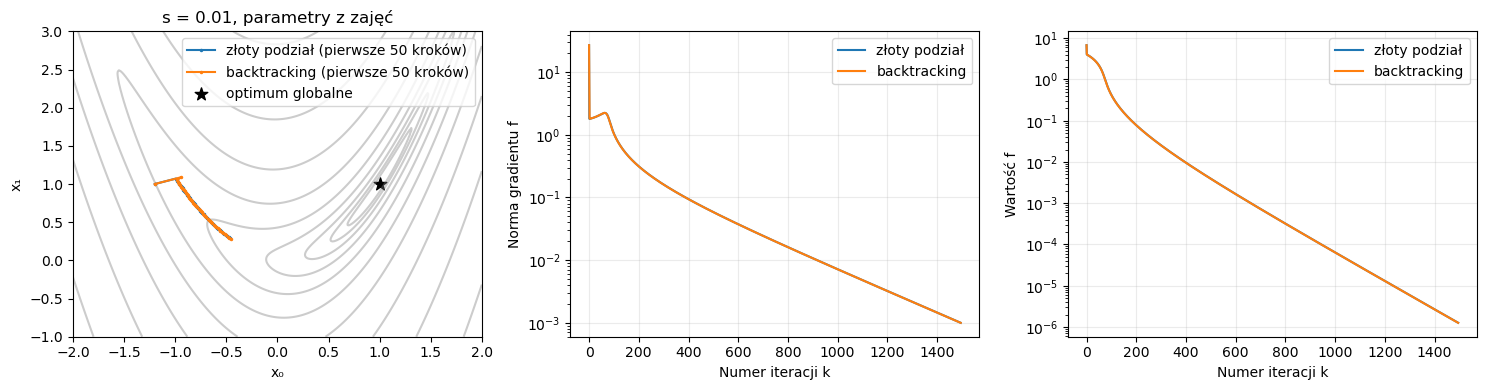

     s | metoda        | kroki | wywołania F | norma ∇F_s | norma ∇f | f końcowe | status
     1 | złoty podział |  1274 |       45827 |   9.91e-06 | 9.91e-06 |  6.29e-11 | OK
     1 | backtracking  |  1106 |        8326 |   9.80e-06 | 9.80e-06 |  7.27e-11 | OK


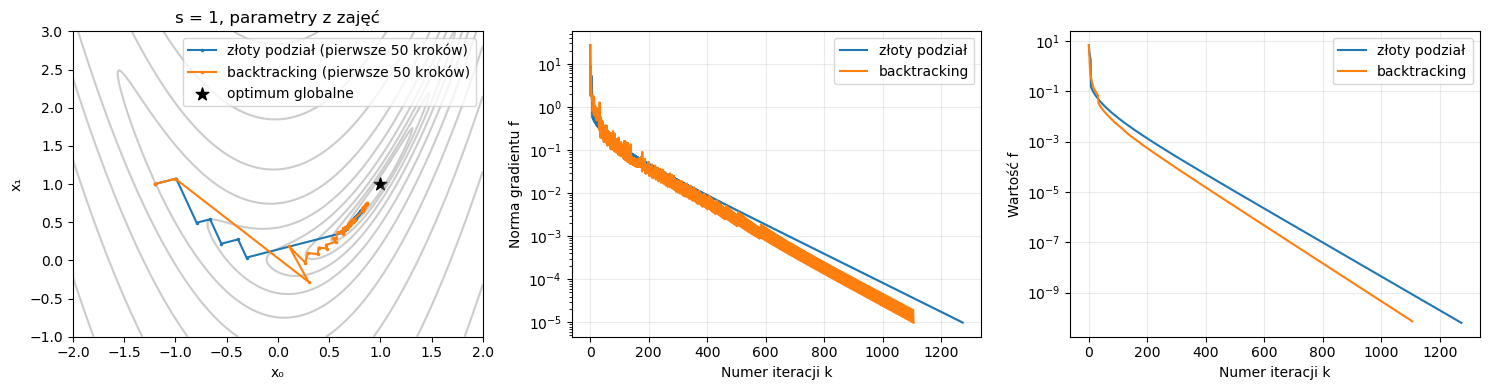

     s | metoda        | kroki | wywołania F | norma ∇F_s | norma ∇f | f końcowe | status
   100 | złoty podział |  1820 |       74566 |   9.91e-06 | 9.91e-08 |  6.27e-15 | OK
   100 | backtracking  |  1069 |       14934 |   9.86e-06 | 9.86e-08 |  9.75e-15 | OK


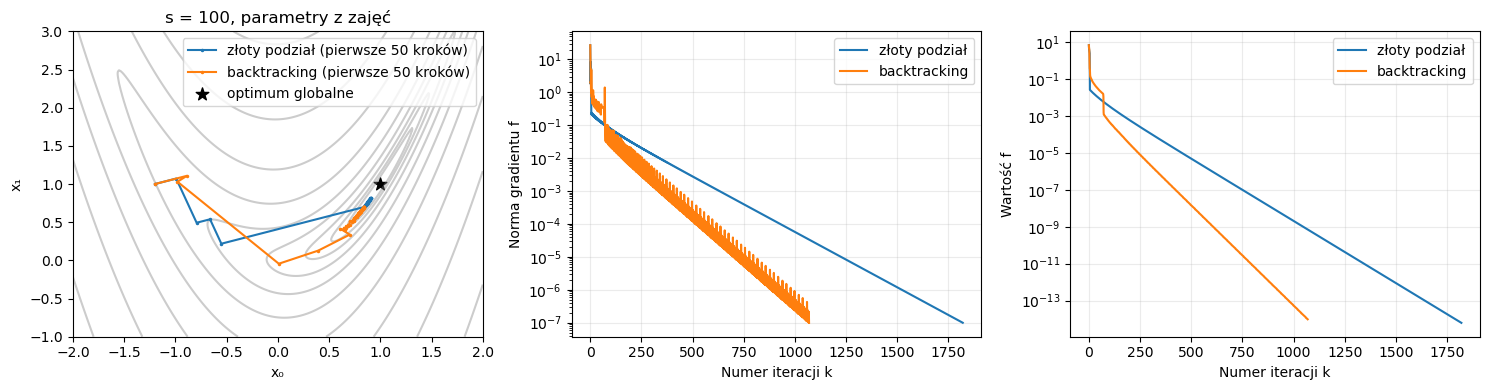

In [25]:
for s in [0.01, 1, 100]:
    compare_scaled(s, steps, "parametry z zajęć")

### Parametry dostosowane do skali

Ponieważ $\nabla F_s=s\nabla f$, długość kroku skalujemy jak $1/s$: złoty podział na $[0,1/s]$, backtracking od $\alpha_0=1/s$. Dla $s=1$ nic się nie zmienia, więc go pomijamy.

     s | metoda        | kroki | wywołania F | norma ∇F_s | norma ∇f | f końcowe | status
  0.01 | złoty podział |   680 |       24443 |   9.92e-06 | 9.92e-04 |  6.30e-07 | OK
  0.01 | backtracking  |   569 |        4245 |   9.63e-06 | 9.63e-04 |  7.94e-07 | OK


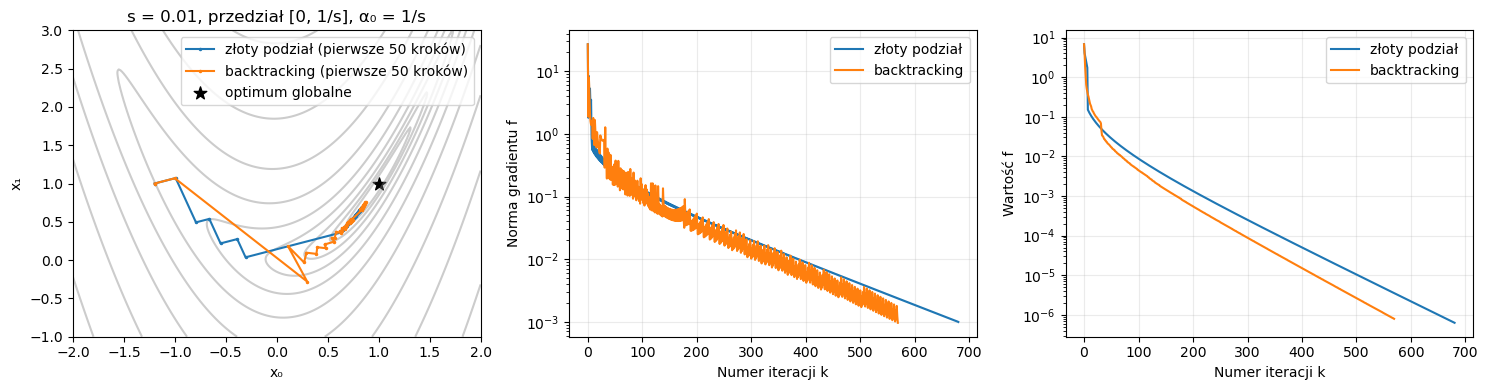

     s | metoda        | kroki | wywołania F | norma ∇F_s | norma ∇f | f końcowe | status
   100 | złoty podział |  1868 |       67211 |   9.93e-06 | 9.93e-08 |  6.32e-15 | OK
   100 | backtracking  |  1639 |       12377 |   9.69e-06 | 9.69e-08 |  7.19e-15 | OK


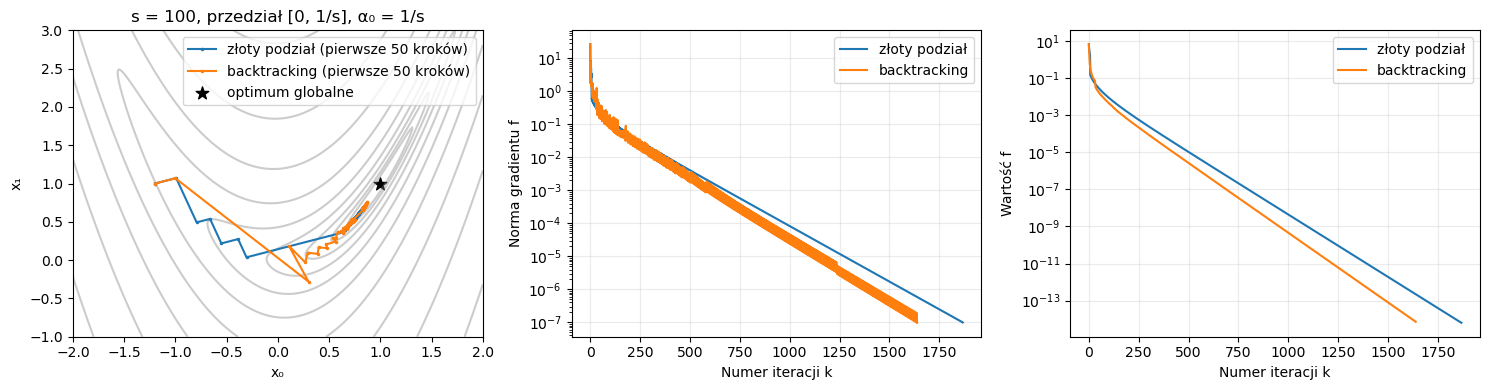

In [26]:
for s in [0.01, 100]:
    compare_scaled(s, adjusted_steps(s), "przedział [0, 1/s], α₀ = 1/s")

**Wnioski:**
- Warunek $\|\nabla F_s\|=s\|\nabla f\|\le10^{-5}$ oznacza $\|\nabla f\|\le10^{-5}/s$, dlatego dokładność rośnie z $s$: końcowe $f\approx10^{-6}$, $10^{-10}$ i $10^{-14}$ dla $s=0{,}01;\,1;\,100$. Wszystkie przebiegi zakończyły się statusem OK.
- Parametry z zajęć: dla $s=0{,}01$ gradient jest 100 razy mniejszy, a krok ograniczony do 1 jest za krótki. Obie metody biorą $\alpha\approx1$, idą tą samą trajektorią i potrzebują 1495 iteracji (złoty podział 49 335 wywołań, backtracking 2 990 = 1495 * 2 :P, warunek Armijo od razu zachodzi). Dla $s=100$ krok (jego długość $\alpha$) trzeba w każdej iteracji skracać: 1820 i 1069 iteracji.
- Po dostosowaniu ($[0,1/s]$, $\alpha_0=1/s$) metody robią te same kroki co dla $s=1$, zmienia się tylko moment zatrzymania: dla $s=0{,}01$ jest 680 i 569 iteracji, a dla $s=100$ jest 1868 i 1639 (ostrzejsza tolerancja na $\|\nabla f\|$).
- Skalowanie funkcji nie zmienia zadania, tylko skalę gradientu, więc długość kroku i tolerancję trzeba do niej dopasować. Backtracking jest we wszystkich przypadkach kilka razy tańszy pod względem wywołań funkcji.

## 2. Skalowanie jednej zmiennej

Dla tej samej funkcji zbadaj
$$
F_s(z_0,z_1)=f(z_0,s z_1),
\qquad s\in\{0.01,1,100\}.
$$

Zaczynaj od $z^{(0)}=(-1.2,1/s)$ i zachowaj parametry doboru kroku z zajęć.

Porównaj koszt obliczeń i trajektorie w oryginalnych współrzędnych. Jak skalowanie zmiennej wpływa na działanie metod? Wystarczy analiza eksperymentalna, bez uzasadnienia teoretycznego.

In [27]:
def F_var(z, s):
    return f(np.array([z[0], s * z[1]]))


def grad_F_var(z, s):
    g = grad_f(np.array([z[0], s * z[1]]))
    return np.array([g[0], s * g[1]])


assert np.isclose(F_var(np.array([-1.2, 1.]), 1.), f(np.array([-1.2, 1.])))
# minimum w z = (1, 1/s), czyli w oryginalnym x = (1, 1)
assert np.allclose(grad_F_var(np.array([1., 1. / 100.]), 100.), [0., 0.])

In [28]:
#Znowu zmodyfikowana funkcja compare, tym razem dla F_var i grad_F_var
def compare_var(s, n_steps=50):
    plot = plt.subplots(1, 3, figsize=(15, 4))
    fig = plot[0]
    axes = plot[1]
    ax_path = axes[0]
    ax_grad = axes[1]
    ax_value = axes[2]
    grid = np.meshgrid(np.linspace(-2, 2, 250), np.linspace(-1, 3, 250))
    u = grid[0]
    v = grid[1]
    ax_path.contour(u, v, (1-u)**2 + a*(v-u*u)**2,
                    levels=np.geomspace(0.1, 1000, 12), colors="grey", alpha=0.4)
    z0 = [-1.2, 1. / s]
    print("     s | metoda        | kroki | wywołania F | norma ∇F_s | f końcowe | x końcowe        | status")
    for name in steps:
        step = steps[name]
        calls = 0

        def counted(z):
            nonlocal calls
            calls += 1
            return F_var(z, s)

        result = gd(counted, lambda z: grad_F_var(z, s), z0, step)
        Z = result[0]
        G = result[1]
        status = result[2]
        X = Z * np.array([1., s])  # powrót do oryginalnych współrzędnych x = (z0, s z1)
        values = [f(x) for x in X]
        print(f"{s:6g} | {name:13s} | {len(Z)-1:5d} | {calls:11d} | "
              f"{G[-1]:10.2e} | {values[-1]:9.2e} | ({X[-1, 0]:6.3f}, {X[-1, 1]:6.3f}) | {status}")
        ax_path.plot(X[:n_steps + 1, 0], X[:n_steps + 1, 1], ".-",
                     label=f"{name} (pierwsze {n_steps} kroków)", markersize=3)
        ax_grad.semilogy(G, label=name)
        ax_value.semilogy(values, label=name)
    ax_path.scatter([1], [1], marker="*", s=90, color="black", label="optimum globalne")
    ax_path.set(xlabel="x₀", ylabel="x₁ = s·z₁", title=f"F_s(z) = f(z₀, s·z₁), s = {s:g}")
    ax_grad.set(xlabel="Numer iteracji k", ylabel="Norma gradientu F_s")
    ax_value.set(xlabel="Numer iteracji k", ylabel="Wartość funkcji")
    ax_path.legend()
    for ax in (ax_grad, ax_value):
        ax.legend()
        ax.grid(alpha=0.25)
    fig.tight_layout()
    plt.show()

     s | metoda        | kroki | wywołania F | norma ∇F_s | f końcowe | x końcowe        | status
  0.01 | złoty podział | 20000 |      695883 |   8.47e-03 |  1.49e-01 | ( 0.626,  0.361) | limit iteracji
  0.01 | backtracking  |    12 |          91 |   9.10e-06 |  3.75e-10 | ( 1.000,  1.000) | OK


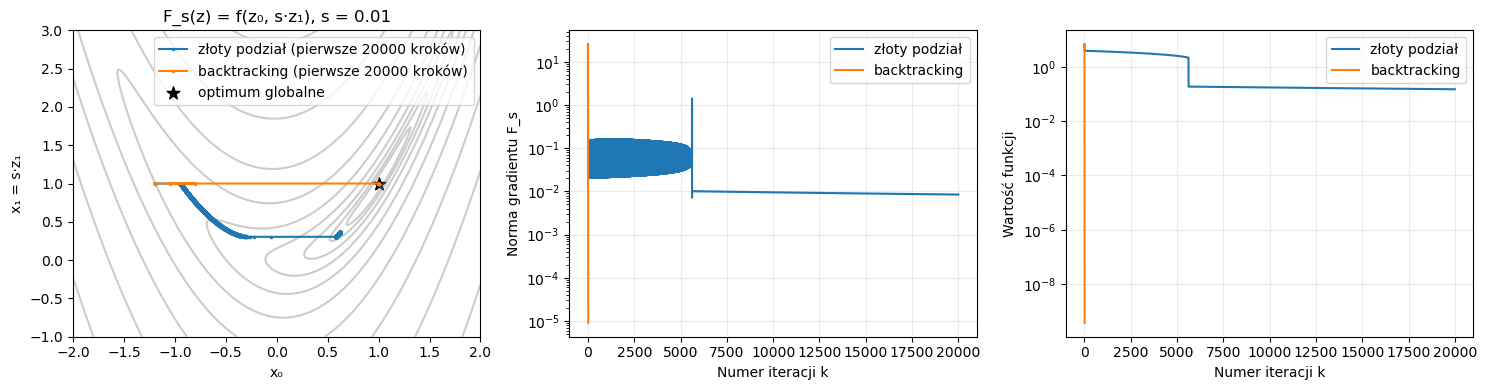

     s | metoda        | kroki | wywołania F | norma ∇F_s | f końcowe | x końcowe        | status
     1 | złoty podział |  1274 |       45827 |   9.91e-06 |  6.29e-11 | ( 1.000,  1.000) | OK
     1 | backtracking  |  1106 |        8326 |   9.80e-06 |  7.27e-11 | ( 1.000,  1.000) | OK


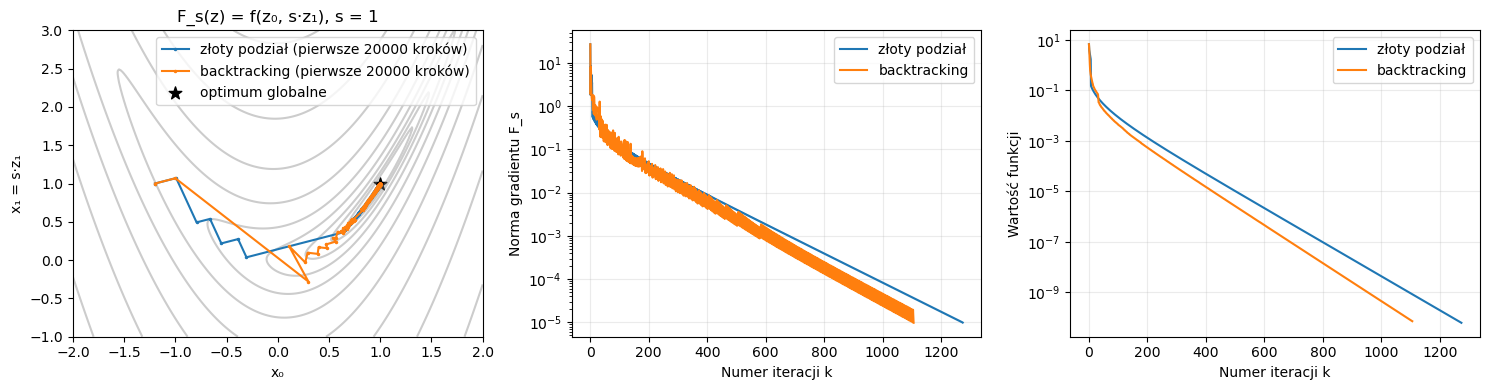

     s | metoda        | kroki | wywołania F | norma ∇F_s | f końcowe | x końcowe        | status
   100 | złoty podział |  5255 |      215610 |   1.00e-05 |  2.49e-11 | ( 1.000,  1.000) | OK
   100 | backtracking  | 20000 |      370324 |   5.12e+00 |  1.91e+00 | (-0.383,  0.145) | limit iteracji


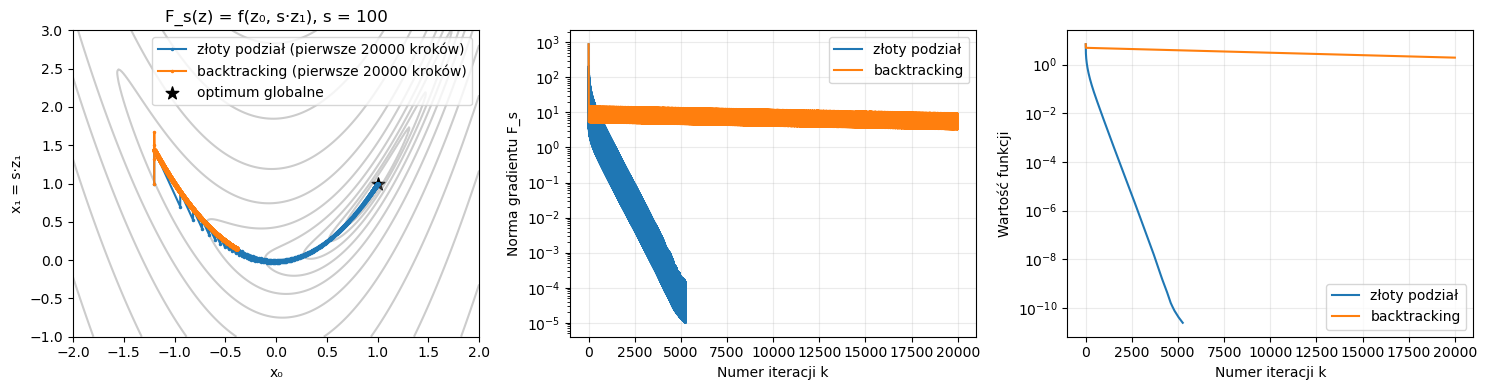

In [29]:
for s in [0.01, 1, 100]:
    compare_var(s, n_steps=20_000)

**Wnioski:**
- Dla $s=1$ jest to zadanie wyjściowe (1274 i 1106 iteracji). Dla $s\neq1$ wyniki zmieniają się mocno i inaczej dla każdej metody.
- $s=0{,}01$: zmiana $z_1$ prawie nie przesuwa $x_1$, więc metody poruszają się praktycznie tylko wzdłuż $x_0$. Złoty podział wybiera minimum na prostej, zatrzymuje się przy $x_0\approx-0{,}95$ i potem bardzo powoli schodzi doliną - limit 20 000 iteracji, $f=0{,}149$, prawie 700 tys. wywołań. Backtracking jednym dużym krokiem przeskoczył do $x_0\approx1$ i, ponieważ startowe $x_1=1$ jest już optymalne, skończył w 12 iteracjach (91 wywołań). To raczej zbieg okoliczności wynikający z punktu startowego niż przewaga metody.
- $s=100$: kierunek $z_1$ staje się bardzo stromy. Backtracking musi zmniejszać krok do ok. $10^{-5}$, przez co $x_0$ prawie się nie zmienia, a $x_1$ oscyluje - limit iteracji, $f=1{,}91$. Złoty podział na przemian robi bardzo krótki krok (poprawia $x_1$) i dłuższy (poprawia $x_0$) i zbiega w 5255 iteracjach (215 610 wywołań), ok. 4 razy wolniej niż dla $s=1$.
- Metoda największego spadku nie jest odporna na skalowanie pojedynczej zmiennej: pogarsza się uwarunkowanie, trajektorie w oryginalnych współrzędnych są zupełnie inne niż dla $s=1$, a to, która metoda zadziała, zależy od $s$.

## 3. Większy wymiar

Zaimplementuj funkcję Rosenbrocka i jej gradient dla każdego $n\geq2$:
$$
f_n(x)=\sum_{i=0}^{n-2}\left[(1-x_i)^2+100(x_{i+1}-x_i^2)^2\right].
$$

Porównaj metody dla $n\in\{2,5,10,20\}$, ze startu $(-1.2,\ldots,-1.2)\in\mathbb{R}^n$, stosując warunek stopu
$$
\|\nabla f_n(x)\|/\sqrt n\leq10^{-5}.
$$

Na wykresach porównuj $f_n/(n-1)$ oraz $\|\nabla f_n\|/\sqrt n$. Jak wymiar wpływa na koszt i skuteczność metod? Czy końcowa wartość funkcji jest bliska minimum globalnemu $0$, osiąganemu w $(1,\ldots,1)$?

In [30]:
def rosen_n(x):
    x = np.asarray(x, dtype=float)
    return np.sum((1 - x[:-1])**2 + 100 * (x[1:] - x[:-1]**2)**2)


def grad_rosen_n(x):
    x = np.asarray(x, dtype=float)
    t = x[1:] - x[:-1]**2
    g = np.zeros_like(x)
    g[:-1] = 2 * (x[:-1] - 1) - 400 * x[:-1] * t
    g[1:] += 200 * t
    return g

In [31]:
# dla n = 2 to funkcja z zajęć (a = 100)
x = np.array([-1.2, 1.])
assert np.isclose(rosen_n(x), rosen(x))
assert np.allclose(grad_rosen_n(x), grad_rosen(x))
# minimum globalne w (1, ..., 1)
assert np.isclose(rosen_n(np.ones(10)), 0.)
assert np.allclose(grad_rosen_n(np.ones(10)), 0.)
# gradient zgodny z ilorazami różnicowymi
x = np.random.default_rng(0).uniform(-2, 2, 6)
h = 1e-6
numerical = np.array([(rosen_n(x + h*e) - rosen_n(x - h*e)) / (2*h) for e in np.eye(6)])
assert np.allclose(grad_rosen_n(x), numerical, rtol=1e-5, atol=1e-4)

In [32]:
def compare_dim(n):
    x0 = np.full(n, -1.2)
    for name in steps:
        step = steps[name]
        calls = 0

        def counted(x):
            nonlocal calls
            calls += 1
            return rosen_n(x)

        # warunek ‖∇f‖/√n ≤ 1e-5 to to samo co ‖∇f‖ ≤ 1e-5·√n
        result = gd(counted, grad_rosen_n, x0, step, eps=1e-5 * np.sqrt(n), max_iter=20_000)
        X = result[0]
        G = result[1]
        status = result[2]
        history[(n, name)] = (X, G)
        print(f"{n:2d} | {name:13s} | {len(X)-1:5d} | {calls:11d} | "
              f"{G[-1]:8.2e} | {G[-1] / np.sqrt(n):8.2e} | "
              f"{rosen_n(X[-1]):8.2e} | {rosen_n(X[-1]) / (n-1):8.2e} | "
              f"{np.max(np.abs(X[-1] - 1)):8.2e} | {status}")


dims = [2, 5, 10, 20]
history = {}
print(" n | metoda        | kroki | wywołania f | ‖∇f‖     | ‖∇f‖/√n  | f        | f/(n-1)  | max|x-1| | status")
for n in dims:
    compare_dim(n)

 n | metoda        | kroki | wywołania f | ‖∇f‖     | ‖∇f‖/√n  | f        | f/(n-1)  | max|x-1| | status
 2 | złoty podział | 11522 |      437655 | 1.41e-05 | 9.99e-06 | 1.42e-10 | 1.42e-10 | 2.39e-05 | OK
 2 | backtracking  | 10885 |      118889 | 1.40e-05 | 9.91e-06 | 1.38e-10 | 1.38e-10 | 2.35e-05 | OK
 5 | złoty podział | 10172 |      391426 | 2.24e-05 | 1.00e-05 | 4.00e-10 | 1.00e-10 | 3.48e-05 | OK
 5 | backtracking  | 14091 |      163048 | 2.23e-05 | 9.96e-06 | 3.39e-10 | 8.47e-11 | 3.20e-05 | OK
10 | złoty podział | 17181 |      669671 | 3.16e-05 | 1.00e-05 | 5.74e-10 | 6.38e-11 | 4.16e-05 | OK
10 | backtracking  | 15789 |      184901 | 3.15e-05 | 9.95e-06 | 6.30e-10 | 7.00e-11 | 4.36e-05 | OK
20 | złoty podział | 18271 |      712155 | 4.47e-05 | 9.99e-06 | 1.16e-09 | 6.12e-11 | 5.92e-05 | OK
20 | backtracking  | 15546 |      182814 | 4.42e-05 | 9.87e-06 | 1.20e-09 | 6.31e-11 | 6.01e-05 | OK


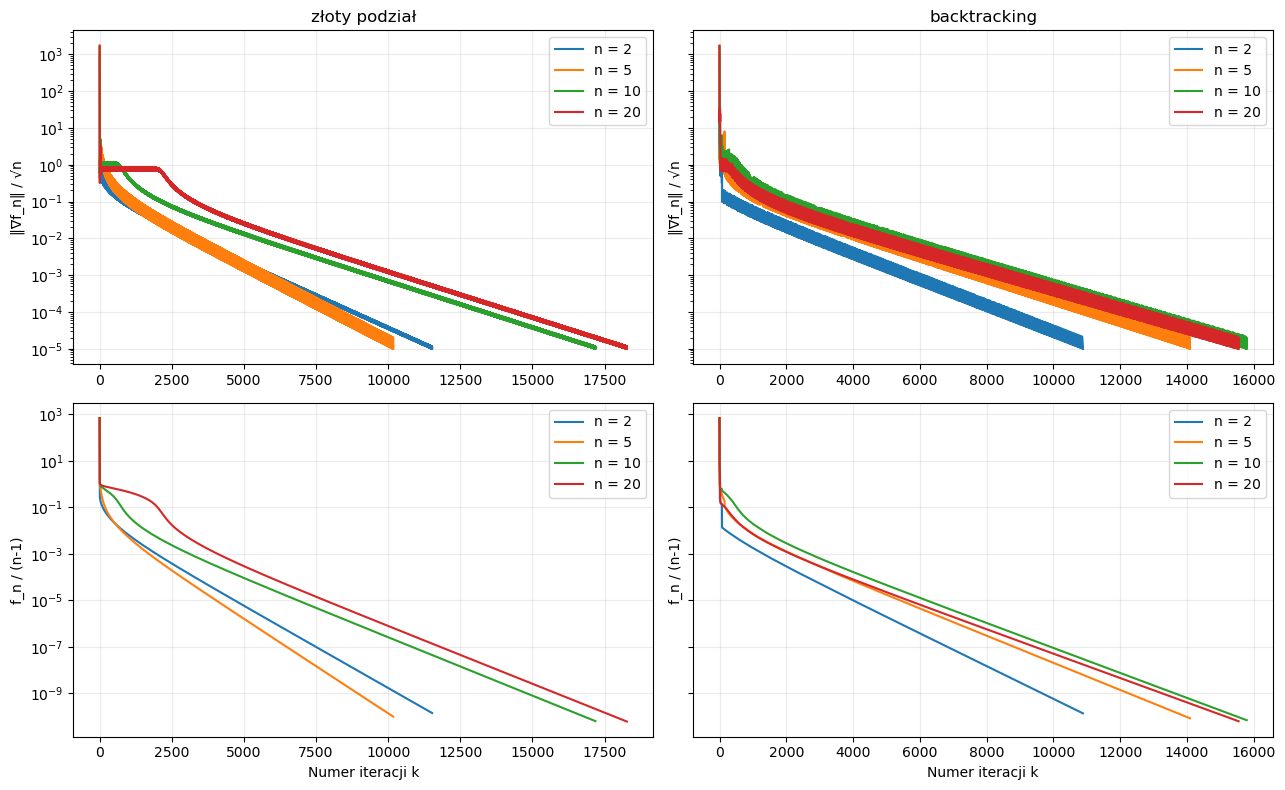

In [33]:
plot = plt.subplots(2, 2, figsize=(13, 8), sharey="row")
fig = plot[0]
axes = plot[1]
for j, name in enumerate(steps):
    for n in dims:
        X, G = history[(n, name)]
        axes[0, j].semilogy(G / np.sqrt(n), label=f"n = {n}")
        axes[1, j].semilogy([rosen_n(x) / (n-1) for x in X], label=f"n = {n}")
    axes[0, j].set(title=name, ylabel="‖∇f_n‖ / √n")
    axes[1, j].set(xlabel="Numer iteracji k", ylabel="f_n / (n-1)")
for ax in axes.flat:
    ax.legend()
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

**Wnioski:**
- Wszystkie przebiegi zakończyły się statusem OK: $f_n/(n-1)\approx10^{-10}$, a $\max_i|x_i-1|\le6\cdot10^{-5}$, więc końcowa wartość jest bliska minimum globalnemu $0$ w $(1,\ldots,1)$.
- Koszt rośnie z wymiarem, choć nie monotonicznie: złoty podział 11 522 → 10 172 → 17 181 → 18 271 iteracji, backtracking 10 885 → 14 091 → 15 789 → 15 546. Dla $n=20$ złoty podział jest już blisko limitu 20 000 iteracji. Do tego każde wywołanie $f_n$ jest droższe, bo kosztuje $O(n)$ działań.
- Na wykresach po szybkim spadku na początku widać wolną, liniową w skali logarytmicznej zbieżność. Dla $n=10$ i $n=20$ złoty podział ma początkowo ok. 2000 iteracji niemal bez postępu ($\|\nabla f_n\|/\sqrt n\approx1$).
- Przy podobnej liczbie iteracji backtracking jest dla każdego $n$ ok. 2,5–4 razy tańszy pod względem wywołań funkcji (np. dla $n=20$: 182 814 wobec 712 155).